In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np
import pandas as pd
from datetime import datetime, date

In [2]:
# Choose a variable:

ds = xr.load_dataset("../Part1_analysis/ERA5_features/grib_files/slp_50_87.grib", engine="cfgrib")
var_daily1 = ds.msl.groupby(ds.msl.time.dt.date).mean()

Ignoring index file '../Part1_analysis/ERA5_features/grib_files/slp_50_87.grib.5b7b6.idx' incompatible with GRIB file


In [3]:
# Choose a variable:

ds = xr.load_dataset("../Part1_analysis/ERA5_features/grib_files/slp_88_25.grib", engine="cfgrib")
var_daily2 = ds.msl.groupby(ds.msl.time.dt.date).mean()

Ignoring index file '../Part1_analysis/ERA5_features/grib_files/slp_88_25.grib.5b7b6.idx' incompatible with GRIB file


In [4]:
var_daily = xr.concat([var_daily1, var_daily2], dim='date')

In [5]:
dates = var_daily.date.data
datetimes = np.zeros_like(dates)
for i in range(len(dates)):
    datetimes[i] = datetime.combine(dates[i], datetime.min.time())

In [6]:
var_daily.coords["time"] = ("date", datetimes)
var_daily = var_daily.swap_dims({"date": "time"})
var_daily = var_daily.reset_coords('date', drop=True)

In [7]:
var_daily = var_daily.reset_coords(['number', 'step', 'surface'], drop=True)
var_daily = var_daily.sel(time=slice("1950-07", "2025-06"))
month = var_daily.time.dt.month
day = var_daily.time.dt.day
var_daily = var_daily.sel(time=~((month == 2) & (day == 29)))
var_daily = var_daily.assign_coords({'month_day': 31*var_daily['time.month'] + var_daily['time.day']})

In [8]:
var_7dMean = var_daily.rolling(time=7, min_periods=7, center=True).mean()
month = var_7dMean.time.dt.month
day = var_7dMean.time.dt.day
var_7dMean = var_7dMean.sel(time=~( ((month==10)&(day<4)) | ((month==2)&(day>25)) ))

In [9]:
weights = np.cos(np.deg2rad(var_daily.latitude))
weights.name = "weights"

In [10]:
var_7dMean_regmean = var_7dMean.weighted(weights).mean(dim=['longitude', 'latitude'])
var_7dMean_regstd = var_7dMean.weighted(weights).std(dim=['longitude', 'latitude'])
var_7dMean_regmin = var_7dMean.min(dim=['longitude', 'latitude'])
var_7dMean_regmax = var_7dMean.max(dim=['longitude', 'latitude'])

In [11]:
var_7dMean_regmean_anom = var_7dMean_regmean.groupby('month_day') - var_7dMean_regmean.sel(time=slice("1950-07", "2010-06")).groupby('month_day').mean()
var_7dMean_regstd_anom = var_7dMean_regstd.groupby('month_day') - var_7dMean_regstd.sel(time=slice("1950-07", "2010-06")).groupby('month_day').mean()
var_7dMean_regmin_anom = var_7dMean_regmin.groupby('month_day') - var_7dMean_regmin.sel(time=slice("1950-07", "2010-06")).groupby('month_day').mean()
var_7dMean_regmax_anom = var_7dMean_regmax.groupby('month_day') - var_7dMean_regmax.sel(time=slice("1950-07", "2010-06")).groupby('month_day').mean()

In [12]:
# Choose appropriate names:

df_var = var_7dMean_regmean_anom.to_dataframe(name='slp_mean')
df_var['slp_std'] = var_7dMean_regstd_anom.to_dataframe()['msl']
df_var['slp_min'] = var_7dMean_regmin_anom.to_dataframe()['msl']
df_var['slp_max'] = var_7dMean_regmax_anom.to_dataframe()['msl']

In [13]:
df_var = df_var.drop(['month_day'], axis=1)
month = df_var.index.month
day = df_var.index.day
df_var_week3 = df_var[((month == 11) & (day >= 13)) | (month == 12) | (month == 1) | ((month == 2) & (day <= 4))]
df_var_week4 = df_var[((month == 11) & (day >= 6)) | (month == 12) | ((month == 1) & (day <= 28))]

In [14]:
df_var_week3

,slp_mean,slp_std,slp_min,slp_max
time,,,,
1950-11-13,-190.856923,106.745561,-683.179688,-355.343750
1950-11-14,-201.501273,87.282897,-593.437500,-299.937500
1950-11-15,-173.693591,45.235528,-512.640625,-375.773438
1950-11-16,-104.614999,-35.242386,-245.085938,-474.835938
1950-11-17,-12.446105,-129.396437,313.226562,-227.398438
...,...,...,...,...
2025-01-31,142.885750,199.483811,-1073.328125,-247.656250
2025-02-01,189.904555,242.205647,-1023.226562,4.906250
2025-02-02,213.362050,324.448268,-1434.257812,208.914062


<Axes: xlabel='time'>

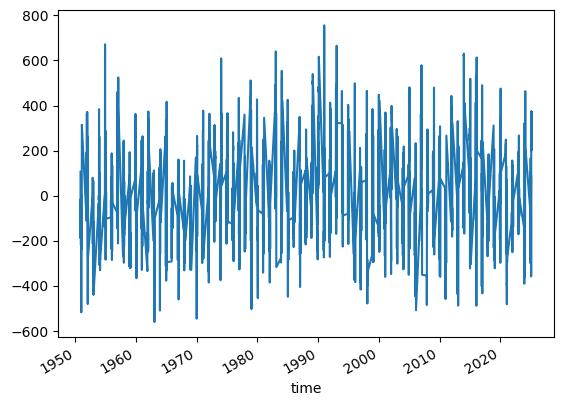

In [18]:
df_var_week3['slp_std'].plot()

In [19]:
# Name files appropriately:

df_var_week3.to_csv('slp_week3.csv')
df_var_week4.to_csv('slp_week4.csv')